In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.interpolate import UnivariateSpline

In [14]:
systems = {
    "N=10" : {
        "N_total" : 10,
        "L"       : 8.03e-6,
        "color"   : "royalblue",
        "marker"  : "^",
        "Np"      : np.array([1, 2, 3, 4, 5, 6, 7, 8, 9]),
        "mean"    : np.array([1.599, 1.965, 1.220, 1.456, 1.225,
                              1.010, 1.120, 1.222, 1.549]),
        "SEM"     : np.array([0.2820, 0.3442, 0.2193, 0.2130, 0.2699,
                              0.1254, 0.2811, 0.2363, 0.3257]),
    },
    "N=30" : {
        "N_total" : 30,
        "L"       : 13.9e-6,
        "color"   : "forestgreen",
        "marker"  : "D",
        "Np"      : np.array([1, 2, 3, 6, 9, 12, 15, 18, 21, 24, 27, 29]),
        "mean"    : np.array([1.852, 1.719, 1.244, 1.137, 0.9049, 0.7512, 
                              0.9852, 0.9050, 0.9796, 1.006, 1.136, 1.451]),
        "SEM"     : np.array([0.3017, 0.2682, 0.2097, 0.1122, 0.07465, 0.1038, 
                              0.1080, 0.1410, 0.1345, 0.1630, 0.1197, 0.1746]),
    },
    "N=50" : {
        "N_total" : 50,
        "L"       : 17.96e-6,
        "color"   : "darkorange",
        "marker"  : "s",
        "Np"      : np.array([1, 2, 3, 4, 5, 10, 15, 20, 25, 30, 35, 40, 45, 48]),
        "mean"    : np.array([1.709, 1.244, 0.8070, 1.503, 1.205, 1.074,
                              0.8225, 0.8020, 0.8009, 0.7524, 0.8006,
                              0.8453, 1.0280, 0.9224]),
        "SEM"     : np.array([0.2002, 0.2175, 0.1036, 0.2028, 0.2066, 0.1344,
                              0.07676, 0.05881, 0.07846, 0.08448, 0.09008,
                              0.1006, 0.1476, 0.1900]),
    },
    "N=70" : {
        "N_total" : 70,
        "L"       : 21.26e-6,
        "color"   : "purple",
        "marker"  : "P",
        "Np"      : np.array([1, 2, 3, 4, 5, 6, 7, 14, 21, 28, 35, 42, 49, 56, 63, 67, 69]),
        "mean"    : np.array([1.433, 0.9578, 1.057, 1.010, 1.088, 0.8567, 0.8717, 0.6555, 0.6850, 0.6147, 0.6911, 0.5660, 0.6897, 0.6683, 0.9215, 1.391, 2.315]),
        "SEM"     : np.array([0.2781, 0.09632, 0.1204, 0.1251, 0.1018, 0.1189, 0.09718, 0.08669, 0.06691, 0.05421, 0.05385, 0.05628, 0.06248, 0.07728, 0.05126, 0.1975, 0.2016]),
    },
    "N=100" : {
        "N_total" : 100,
        "L"       : 25.4e-6,
        "color"   : "crimson",
        "marker"  : "o",
        "Np"      : np.array([1, 2, 3, 4, 5, 6, 7, 8, 10, 20, 30, 40,
                              50, 60, 70, 80, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99]),
        "mean"    : np.array([1.145, 0.5743, 0.5940, 0.5727, 0.4906, 0.5174,
                              0.4570, 0.3685, 0.3485, 0.3244, 0.3814, 0.3427,
                              0.2975, 0.3247, 0.2806, 0.3775, 0.3835, 0.4553,
                              0.4169, 0.5379, 0.4048, 0.6903, 0.5712, 0.6524,
                              0.7594, 1.128]),
        "SEM"     : np.array([0.1168, 0.06974, 0.09745, 0.1121, 0.06939, 0.05720,
                              0.05287, 0.05406, 0.02456, 0.02126, 0.03377, 0.03826,
                              0.02303, 0.01853, 0.02140, 0.03272, 0.03263, 0.03505,
                              0.04165, 0.06027, 0.06855, 0.09844, 0.07819, 0.08662,
                              0.1213, 0.1320]),
    },
    "N=200" : {
        "N_total" : 200,
        "L"       : 35.92e-6,
        "color"   : "brown",
        "marker"  : "+",
        "Np"      : np.array([2, 4, 6, 8, 
                              10, 12 ,14, 16, 
                              18, 20, 40, 60, 
                              80, 100, 120, 160, 
                              180, 182, 184, 186, 
                              188, 190, 192, 194, 
                              196, 198]),
        "mean"    : np.array([1.097, 1.075, 0.8053, 0.7522, 0.8476,
                              0.6749, 0.7527, 0.6687, 0.6663, 0.6757, 
                              0.5463, 0.5612, 0.5050,  0.4830, 0.4867, 
                              0.5216, 0.6966, 0.6885, 0.6779, 0.7035, 
                              0.7453, 0.9456, 0.7788, 1.149, 1.196, 1.629]),
        "SEM"     : np.array([0.1385, 0.1485, 0.1008, 0.1045, 0.1030,
                              0.09131, 0.07753, 0.03816, 0.05853, 0.06184, 
                              0.03837, 0.02732, 0.02876, 0.02390, 0.04684, 
                              0.05216 , 0.06966, 0.08016, 0.04862, 
                              0.08801, 0.06016, 0.08549, 0.06112, 
                              0.1328, 0.1788, 0.2752]),
    },
}

In [15]:
# PARTICLE GEOMETRY (same across all systems)
d_probe = 2.0e-6
d_meth  = 1.0e-6
A_p     = np.pi * (d_probe / 2)**2
A_m     = np.pi * (d_meth  / 2)**2

def np_to_phi(n, N_total, L):
    """Area fraction for a given Np, N_total, and box side L."""
    n_f   = N_total - n
    A_box = L**2
    return (n * A_p + n_f * A_m) / A_box

In [16]:
# CALDERA FIT FUNCTION
# T(Np) = a/Np^alpha + b*Np^beta + c
def caldera_model(n, a, alpha, b, beta, c):
    return a / (n**alpha) + b * (n**beta) + c

def fit_caldera(Np, mean, SEM):
    """
    Fit the caldera model. Returns (popt, perr, success).
    Falls back gracefully if the fit does not converge.
    """
    p0     = [1.0, 0.5, 1e-4, 2.0, 0.2]
    bounds = ([0, 0.01, 0,    0.5, 0],
              [10, 3.0,  1,   6.0, 5])
    try:
        popt, pcov = curve_fit(
            caldera_model, Np, mean,
            p0=p0, bounds=bounds,
            sigma=SEM, absolute_sigma=True,
            maxfev=20000
        )
        perr = np.sqrt(np.diag(pcov))
        return popt, perr, True
    except RuntimeError:
        return None, None, False

In [17]:
# PROCESS EACH SYSTEM: fit, extract summary statistics
results = {}

print("=" * 65)
# print(f"{'Parameter':<12} {'N=10':>15} {'N=30':>15}{'N=50':>15}{'N=70':>15} {'N=100':>15}{'N=200':>15}")
print(f"{'Parameter':<12} {'N=100':>15}{'N=200':>15}")
print("=" * 65)

for name, sys in systems.items():
    Np_arr  = sys["Np"]
    mean    = sys["mean"]
    SEM_arr = sys["SEM"]
    std_arr = SEM_arr * np.sqrt(10)
    N_total = sys["N_total"]
    L       = sys["L"]

    # Phi array for this system
    phi_arr = np.array([np_to_phi(n, N_total, L) for n in Np_arr])

    # Dense grid in Np space for smooth curves
    Np_dense  = np.linspace(Np_arr.min(), Np_arr.max(), 500)
    phi_dense = np.array([np_to_phi(n, N_total, L) for n in Np_dense])

    # Caldera parametric fit
    popt, perr, ok = fit_caldera(Np_arr, mean, SEM_arr)

    if ok:
        fit_curve = caldera_model(Np_dense, *popt)
        # Find minimum of fit curve
        min_idx   = np.argmin(fit_curve)
        Np_min    = Np_dense[min_idx]
        phi_min   = phi_dense[min_idx]
        T_min     = fit_curve[min_idx]
    else:
        fit_curve = None
        Np_min = Np_arr[np.argmin(mean)]
        phi_min = np_to_phi(Np_min, N_total, L)
        T_min  = np.min(mean)

    # Spline fit for visual smoothness
    weights = 1.0 / (SEM_arr + 1e-6)
    spline  = UnivariateSpline(Np_arr, mean, w=weights, k=min(4, len(Np_arr)-1),
                               s=len(Np_arr) * 0.8)
    spline_curve = spline(Np_dense)

    # Spline fit to SD
    spline_sd    = UnivariateSpline(Np_arr, std_arr,
                                    w=np.ones_like(std_arr),
                                    k=min(4, len(Np_arr)-1),
                                    s=len(Np_arr) * 0.5)
    spline_sd_curve = np.clip(spline_sd(Np_dense), 0, None)

    # Store everything
    results[name] = {
        "Np_arr"        : Np_arr,
        "mean"          : mean,
        "SEM"           : SEM_arr,
        "std"           : std_arr,
        "phi_arr"       : phi_arr,
        "Np_dense"      : Np_dense,
        "phi_dense"     : phi_dense,
        "fit_curve"     : fit_curve,
        "spline_curve"  : spline_curve,
        "spline_sd"     : spline_sd_curve,
        "popt"          : popt,
        "perr"          : perr,
        "fit_ok"        : ok,
        "Np_min"        : Np_min,
        "phi_min"       : phi_min,
        "T_min"         : T_min,
        "color"         : sys["color"],
        "marker"        : sys["marker"],
        "N_total"       : N_total,
        "L"             : L,
        "phi_range"     : (phi_arr.min()*100, phi_arr.max()*100),
    }

# Print parameter table
param_names = ["a", "alpha", "b", "beta", "c"]
for i, pname in enumerate(param_names):
    row = f"{pname:<12}"
    # for name in ["N=10", "N=30" ,"N=50", "N=70", "N=100", "N=200"]:
    for name in ["N=100", "N=200"]:    
        r = results[name]
        if r["fit_ok"]:
            row += f"  {r['popt'][i]:>6.4f}±{r['perr'][i]:.4f}"
        else:
            row += f"  {'N/A':>15}"
    print(row)

print("-" * 65)
summary_rows = [
    ("Np* (fit)",   "Np_min",  "{:.1f}"),
    ("phi* (%)",    "phi_min", "{:.1f}%"),
    ("T_min (s)",   "T_min",   "{:.4f}"),
]
for label, key, fmt in summary_rows:
    row = f"{label:<12}"
    # for name in ["N=10", "N=30","N=50", "N=70","N=100"]:
    for name in ["N=100", "N=200"]:
        val = results[name][key]
        if key == "phi_min":
            row += f"  {val*100:>15.2f}%"
        else:
            row += f"  {val:>15.4f}"
    print(row)
print("=" * 65)

Parameter              N=100          N=200
a             0.7730±0.0937  1.2685±0.4790
alpha         0.8352±0.1661  0.2181±0.2159
b             0.0000±0.0000  0.0000±0.0000
beta          6.0000±1.9537  4.4920±1.7992
c             0.2642±0.0317  0.0004±0.6534
-----------------------------------------------------------------
Np* (fit)             48.5271         100.9820
phi* (%)                29.90%            30.62%
T_min (s)              0.2986           0.4866


<>:53: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:53: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\VENSER\AppData\Local\Temp\ipykernel_15384\4017581488.py:53: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  label=f'Min at $N_p^*$={r["Np_min"]:.1f} ($\phi^*$={r["phi_min"]*100:.1f}%)'


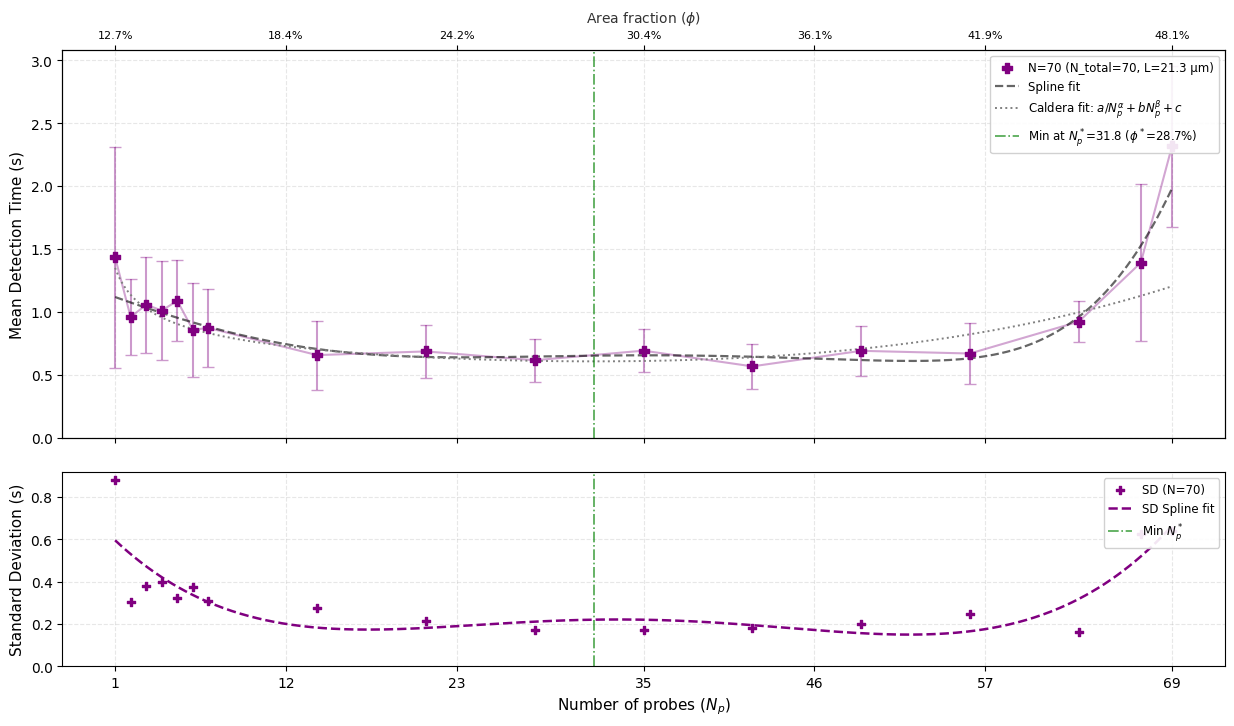

In [18]:
# Change this key to plot any system size (e.g., "N=10", "N=100", "N=200")
TARGET_SYSTEM = "N=70"

# Retrieve data for the specified system
r = results[TARGET_SYSTEM]
name = TARGET_SYSTEM

# Create a 2-panel figure sharing the exact x-axis
fig, (ax_mean, ax_sd) = plt.subplots(
    2, 1, figsize=(15, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1], "hspace": 0.12}
)

# Extract range & compute relative 5% padding so it scales dynamically for any system
np_min, np_max = r["Np_arr"].min(), r["Np_arr"].max()
x_range = np_max - np_min
pad = x_range * 0.05 if x_range > 0 else 0.5

# ==========================================
# TOP PANEL: Mean Detection Time vs. Np
# ==========================================
ax_mean.errorbar(
    r["Np_arr"], r["mean"], yerr=r["std"],
    fmt='none', ecolor=r["color"], alpha=0.4,
    elinewidth=1.5, capsize=4
)
ax_mean.plot(
    r["Np_arr"], r["mean"],
    linestyle='-', color=r["color"], alpha=0.35
)
ax_mean.scatter(
    r["Np_arr"], r["mean"],
    marker=r["marker"], zorder=4, color=r["color"], s=50,
    label=f'{name} (N_total={r["N_total"]}, L={r["L"]*1e6:.1f} µm)'
)

# Spline fit
ax_mean.plot(
    r["Np_dense"], r["spline_curve"],
    color='black', linewidth=1.6, linestyle='--', alpha=0.6,
    label='Spline fit'
)

# Parametric caldera fit
if r["fit_ok"]:
    ax_mean.plot(
        r["Np_dense"], r["fit_curve"],
        color='gray', linewidth=1.4, linestyle=':',
        label=r'Caldera fit: $a/N_p^\alpha + bN_p^\beta + c$'
    )
    ax_mean.axvline(
        r["Np_min"], color='green', linewidth=1.2,
        linestyle='-.', alpha=0.7,
        label=f'Min at $N_p^*$={r["Np_min"]:.1f} ($\phi^*$={r["phi_min"]*100:.1f}%)'
    )

ax_mean.set_ylabel("Mean Detection Time (s)", fontsize=11)
# ax_mean.set_title(f'{name}: Mean First-Passage Detection Time & SD', fontsize=12, fontweight='bold', pad=25)
ax_mean.legend(fontsize=8.5, loc='upper right', framealpha=0.9)
ax_mean.grid(True, linestyle='--', alpha=0.3)
ax_mean.set_ylim(bottom=0)

# Set padded x-limits
ax_mean.set_xlim(np_min - pad, np_max + pad)

# ==========================================
# TOP SECONDARY AXIS: Area fraction (phi)
# ==========================================
ax_top = ax_mean.twiny()
ax_top.set_xlim(ax_mean.get_xlim())

# Generate ticks starting EXACTLY at np_min and ending EXACTLY at np_max
num_ticks = min(7, len(np.unique(r["Np_arr"])))
tick_Np = np.linspace(np_min, np_max, num_ticks).astype(int)
tick_Np = np.unique(tick_Np)

# Synchronize bottom and top ticks
ax_mean.set_xticks(tick_Np)
ax_top.set_xticks(tick_Np)

ax_top.set_xticklabels(
    [f"{np_to_phi(n, r['N_total'], r['L'])*100:.1f}%" for n in tick_Np],
    fontsize=8
)
ax_top.set_xlabel(r"Area fraction ($\phi$)", fontsize=10, color='black', alpha=0.8, labelpad=6)

# ==========================================
# BOTTOM PANEL: Standard Deviation vs. Np
# ==========================================
ax_sd.scatter(
    r["Np_arr"], r["std"],
    marker=r["marker"], color=r["color"], zorder=4, s=40,
    label=f'SD ({name})'
)

# Plot spline_sd against Np_dense for proper coordinate alignment
ax_sd.plot(
    r["Np_dense"], r["spline_sd"],
    color=r["color"], linewidth=1.8, linestyle='--',
    label='SD Spline fit'
)

if r["fit_ok"]:
    ax_sd.axvline(
        r["Np_min"], color='green', linewidth=1.2,
        linestyle='-.', alpha=0.7, label=r'Min $N_p^*$'
    )

ax_sd.set_xlabel("Number of probes ($N_p$)", fontsize=11)
ax_sd.set_ylabel("Standard Deviation (s)", fontsize=11)
ax_sd.legend(fontsize=8.5, loc='upper right', framealpha=0.9)
ax_sd.grid(True, linestyle='--', alpha=0.3)
ax_sd.set_ylim(bottom=0)

# Save and show
clean_filename = name.replace("=", "_").replace(" ", "_")
# plt.savefig(f"caldera_individual_{clean_filename}.jpg", dpi=300, bbox_inches='tight')
# plt.savefig(f"caldera_individual_{clean_filename}.pdf", dpi=300, bbox_inches='tight')
plt.show()

<>:31: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:31: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\VENSER\AppData\Local\Temp\ipykernel_15384\3212250541.py:31: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  label=f'Min at $N_p^*$={r["Np_min"]:.1f} ($\phi^*$={r["phi_min"]*100:.1f}%)')
C:\Users\VENSER\AppData\Local\Temp\ipykernel_15384\3212250541.py:54: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


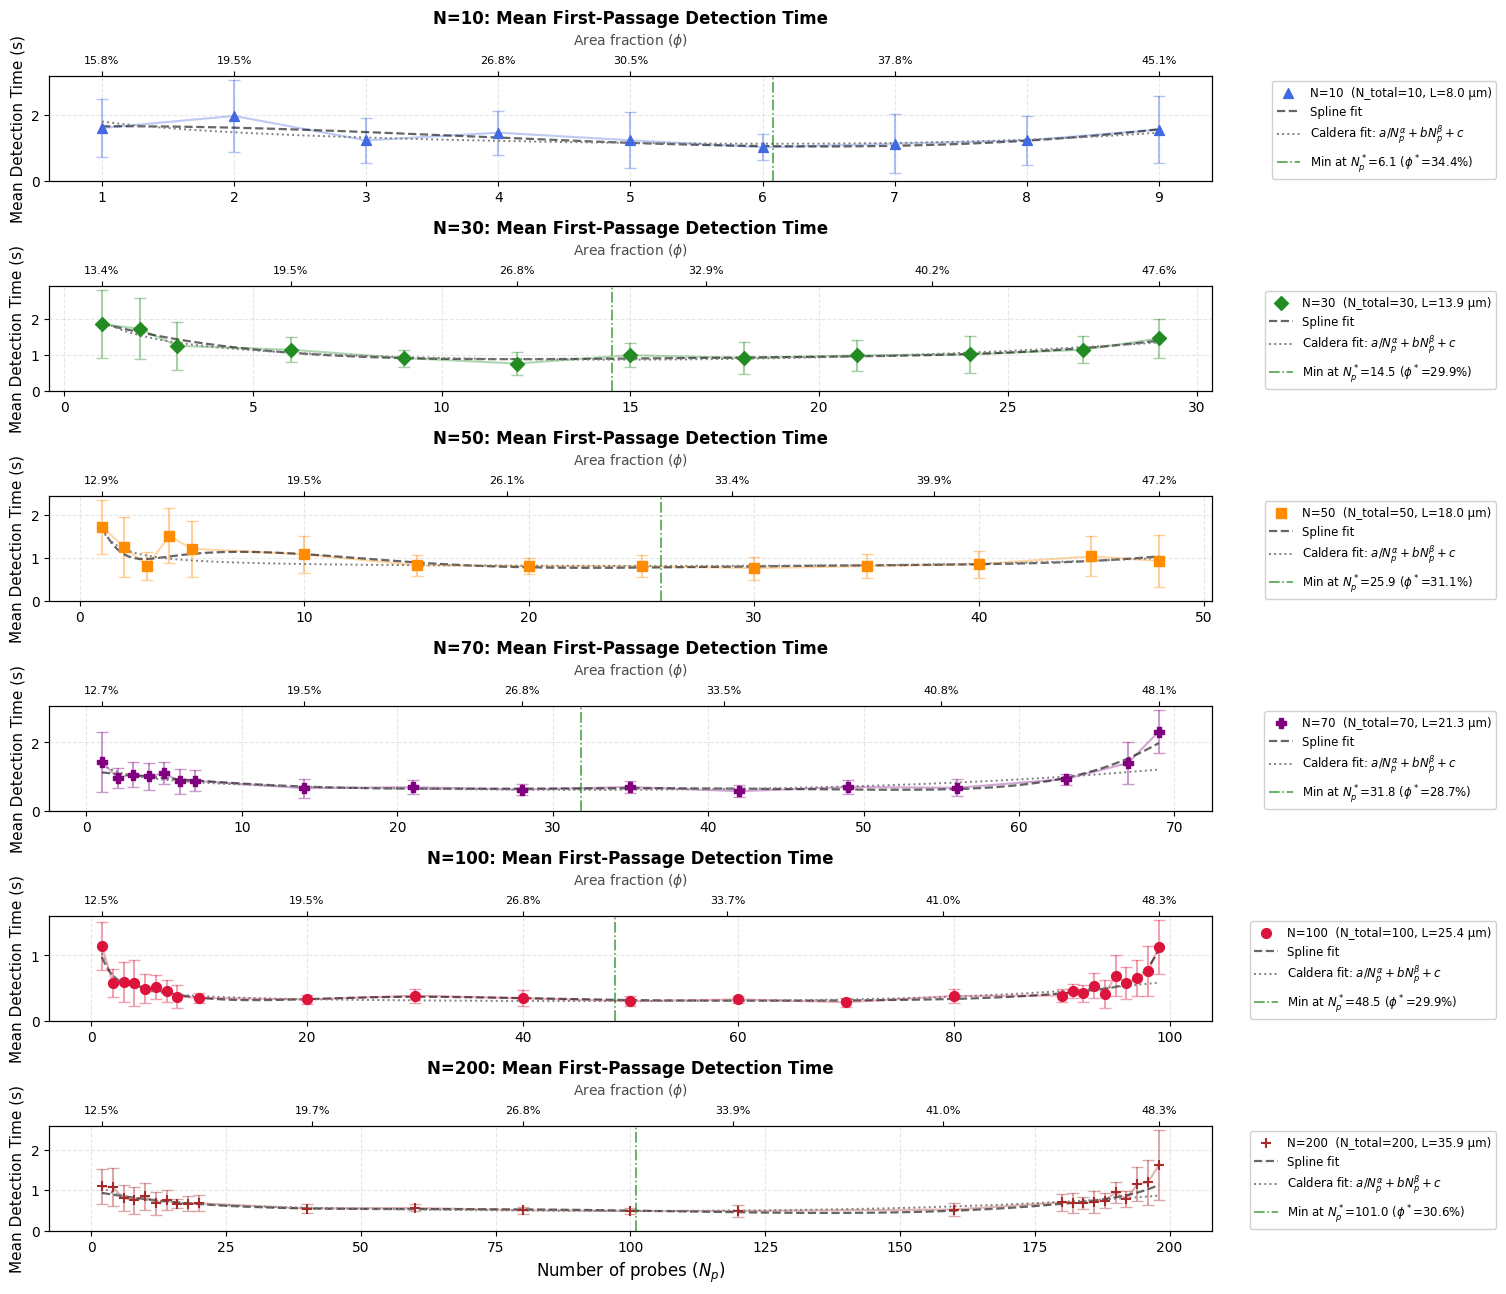

In [19]:
# FIGURE 1: Mean Detection Time vs Np  (with caldera fits)
# Each system on its own row; shared x-axis is phi fraction
# Layout: 3 rows x 1 col, each with its own top phi axis

fig1, axes = plt.subplots(6, 1, figsize=(15, 15),
                           gridspec_kw={"hspace": 1})

for ax, (name, r) in zip(axes, results.items()):
    std = r["std"]
    ax.errorbar(r["Np_arr"], r["mean"], yerr=std,
                fmt='none', ecolor=r["color"], alpha=0.4,
                elinewidth=1.5, capsize=4)
    ax.plot(r["Np_arr"], r["mean"],
            linestyle='-', color=r["color"], alpha=0.35)
    ax.scatter(r["Np_arr"], r["mean"],
               marker=r["marker"], zorder=4, color=r["color"], s=50,
               label=f'{name}  (N_total={r["N_total"]}, L={r["L"]*1e6:.1f} µm)')

    # Spline
    ax.plot(r["Np_dense"], r["spline_curve"],
            color='black', linewidth=1.6, linestyle='--', alpha=0.6,
            label='Spline fit')

    # Parametric caldera
    if r["fit_ok"]:
        ax.plot(r["Np_dense"], r["fit_curve"],
                color='gray', linewidth=1.4, linestyle=':',
                label=r'Caldera fit: $a/N_p^\alpha + bN_p^\beta + c$')
        ax.axvline(r["Np_min"], color='green', linewidth=1.2,
                   linestyle='-.', alpha=0.7,
                   label=f'Min at $N_p^*$={r["Np_min"]:.1f} ($\phi^*$={r["phi_min"]*100:.1f}%)')

    ax.set_ylabel("Mean Detection Time (s)", fontsize=11)
    ax.set_title(f'{name}: Mean First-Passage Detection Time', fontsize=12, fontweight='bold')
    ax.legend(fontsize=8.5, bbox_to_anchor = (1.25,1), loc='upper right', framealpha=0.9)
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_ylim(bottom=0)

    # Top axis: area fraction
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    # Pick ~6 evenly spaced Np values for top ticks
    tick_Np = np.linspace(r["Np_arr"].min(), r["Np_arr"].max(), 6).astype(int)
    tick_Np = np.unique(np.clip(tick_Np, r["Np_arr"].min(), r["Np_arr"].max()))
    ax_top.set_xticks(tick_Np)
    ax_top.set_xticklabels(
        [f"{np_to_phi(n, r['N_total'], r['L'])*100:.1f}%" for n in tick_Np],
        fontsize=8
    )
    ax_top.set_xlabel(r"Area fraction ($\phi$)", fontsize=10, color='black', alpha=0.7, labelpad=8)

axes[-1].set_xlabel("Number of probes ($N_p$)", fontsize=12)

plt.tight_layout()
# plt.savefig("caldera_individual_panels.jpg",dpi=300, bbox_inches='tight')
# plt.savefig("caldera_individual_panels.pdf",dpi=300, bbox_inches='tight')
plt.show()

C:\Users\VENSER\AppData\Local\Temp\ipykernel_15384\2875781274.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


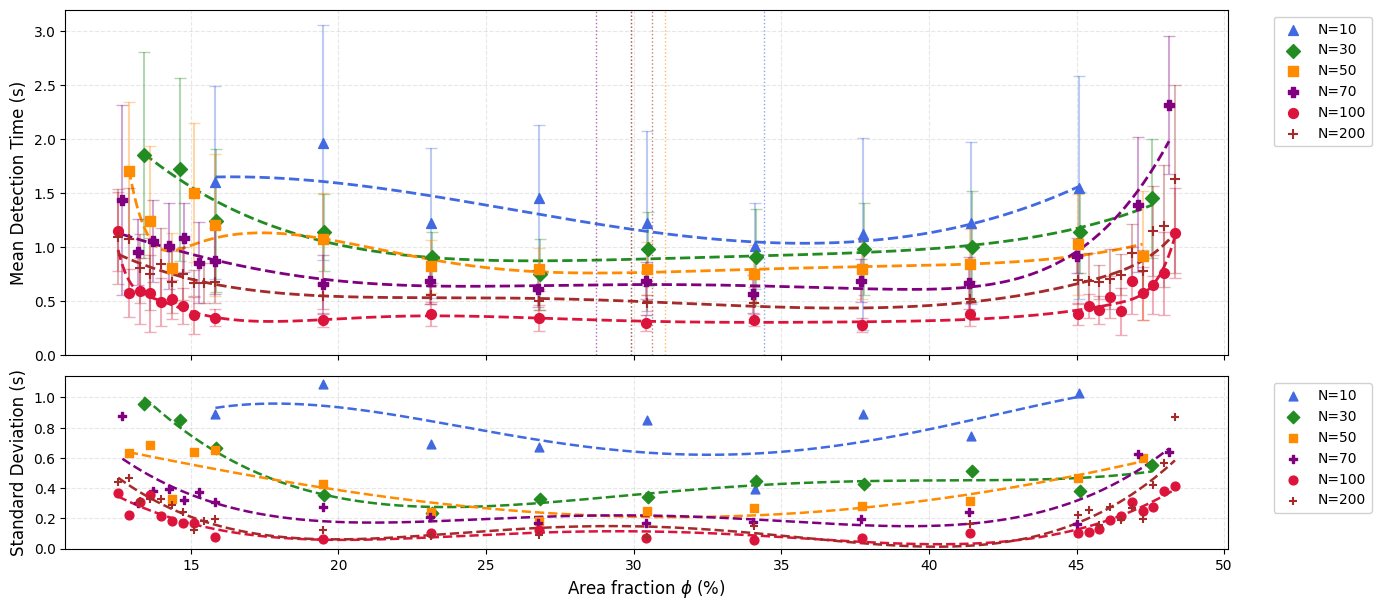

In [20]:
# FIGURE 2: Overlay all systems on phi axis for direct comparison
# x-axis is phi (not Np) so all three systems align
fig2, (ax_mean, ax_sd) = plt.subplots(2, 1, figsize=(15, 7), sharex=True, gridspec_kw={"height_ratios":[2,1], "hspace":0.08})

for name, r in results.items():
    # Mean detection time vs phi
    ax_mean.errorbar(r["phi_arr"]*100, r["mean"], yerr=r["std"], fmt='none', ecolor=r["color"], alpha=0.35, elinewidth=1.5, capsize=4)
    ax_mean.scatter(r["phi_arr"]*100, r["mean"], marker=r["marker"], color=r["color"], zorder=4, s=50, label=f'{name}')
    ax_mean.plot(r["phi_dense"]*100, r["spline_curve"], color=r["color"], linewidth=2, linestyle='--')
    if r["fit_ok"]: ax_mean.axvline(r["phi_min"]*100, color=r["color"], linewidth=1, linestyle=':', alpha=0.6)

    # SD vs phi
    ax_sd.scatter(r["phi_arr"]*100, r["std"], marker=r["marker"], color=r["color"], zorder=4, s=40, label=f'{name}')
    ax_sd.plot(r["phi_dense"]*100, r["spline_sd"], color=r["color"], linewidth=1.8, linestyle='--')

ax_mean.set_ylabel("Mean Detection Time (s)", fontsize=12)
# ax_mean.set_title("Comparison of caldera across different system sizes\n" "(aligned by area fraction $\\phi$)", fontsize=13, fontweight='bold')
ax_mean.legend(fontsize=10, loc='upper right',bbox_to_anchor = (1.13,1), framealpha=0.9)
ax_mean.grid(True, linestyle='--', alpha=0.3)
ax_mean.set_ylim(bottom=0)

ax_sd.set_xlabel(r"Area fraction $\phi$ (%)", fontsize=12)
ax_sd.set_ylabel("Standard Deviation (s)", fontsize=12)
ax_sd.legend(fontsize=10, loc='upper right',bbox_to_anchor = (1.13,1), framealpha=0.9)
ax_sd.grid(True, linestyle='--', alpha=0.3)
ax_sd.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig("caldera_overlay_phi.png", dpi=300, bbox_inches='tight')
# plt.savefig("caldera_overlay_phi.pdf", dpi=300, bbox_inches='tight')
plt.show()

Figure 3 (parameter table) saved.


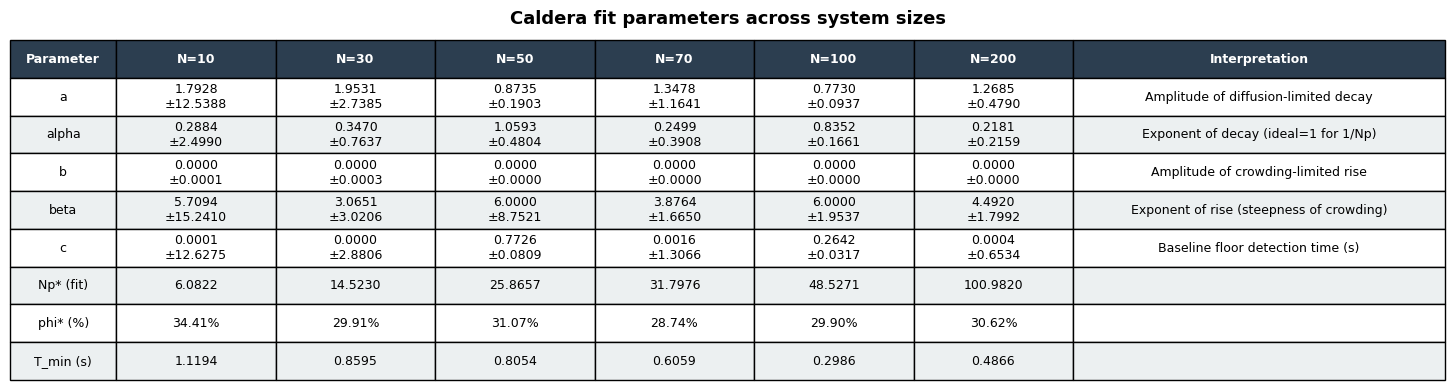

In [21]:
# FIGURE 3: Parameter comparison table as a figure
fig3, ax_tab = plt.subplots(figsize=(15, 4))
ax_tab.axis('off')

# col_labels = ["Parameter", "N=10", "N=30" ,"N=50","N=70", "N=100", "Interpretation"]
col_labels = ["Parameter", "N=10", "N=30" ,"N=50","N=70", "N=100", "N=200", "Interpretation"]
interp = {
    "a"      : "Amplitude of diffusion-limited decay",
    "alpha"  : "Exponent of decay (ideal=1 for 1/Np)",
    "b"      : "Amplitude of crowding-limited rise",
    "beta"   : "Exponent of rise (steepness of crowding)",
    "c"      : "Baseline floor detection time (s)",
    "Np*"    : "Optimal probe number (minimum T)",
    "phi* %" : "Optimal area fraction at minimum T",
    "T_min"  : "Minimum mean detection time (s)",
}

table_data = []
for i, pname in enumerate(param_names):
    row = [pname]
    # for name in ["N=100", "N=200"]:
    for name in ["N=10", "N=30" ,"N=50","N=70", "N=100", "N=200"]:
        r = results[name]
        if r["fit_ok"]:
            row.append(f"{r['popt'][i]:.4f}\n±{r['perr'][i]:.4f}")
        else:
            row.append("N/A")
    row.append(interp[pname])
    table_data.append(row)

# Summary rows
for label, key, fmt in summary_rows:
    row = [label]
    for name in ["N=10", "N=30" ,"N=50","N=70", "N=100", "N=200"]:
    # for name in ["N=100", "N=200"]:
        r = results[name]
        if key == "phi_min":
            row.append(f"{r[key]*100:.2f}%")
        else:
            row.append(f"{r[key]:.4f}")
    row.append(interp.get(label.strip(), ""))
    table_data.append(row)

tbl = ax_tab.table(
    cellText=table_data,
    colLabels=col_labels,
    cellLoc='center',
    loc='center',
    colWidths=[0.10, 0.15, 0.15, 0.15,0.15 , 0.15, 0.15, 0.35]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 2.2)

# Style header
for j in range(len(col_labels)):
    tbl[0, j].set_facecolor('#2c3e50')
    tbl[0, j].set_text_props(color='white', fontweight='bold')

# Alternate row shading
for i in range(1, len(table_data)+1):
    for j in range(len(col_labels)):
        tbl[i, j].set_facecolor('#ecf0f1' if i % 2 == 0 else 'white')

ax_tab.set_title("Caldera fit parameters across system sizes",
                 fontsize=13, fontweight='bold', pad=20)

plt.tight_layout()
# plt.savefig("caldera_parameter_table.jpg",
#             dpi=300, bbox_inches='tight')
# plt.savefig("caldera_parameter_table.pdf",
#             dpi=300, bbox_inches='tight')
print("Figure 3 (parameter table) saved.")
plt.show()
plt.show()

In [22]:
# ---- RIM PROMINENCE RATIO & CALDERA CLASSIFICATION ----
def classify_caldera(r, rpr_shield=2.0, z_thresh=2.0):
    """
    Classify a system's caldera profile using the Rim Prominence Ratio (RPR)
    and a significance z-score on the crowding-side rise.

    RPR = T_edge / T_floor
        T_edge  : raw measured <T> at the most crowded sampled Np
        T_floor : fitted caldera minimum (falls back to data minimum if fit failed)

    z-score tests whether T_edge is statistically distinguishable from the
    data-floor point, using their propagated SEMs.

    Categories:
      Type I   - Incipient (Latent) Caldera   : rise not statistically resolved (z < z_thresh)
      Type II  - Shield Caldera                : resolved, but RPR < rpr_shield
      Type III - Steep-Walled (Stratovolcano)  : resolved and RPR >= rpr_shield
    """
    Np_arr, mean, SEM = r["Np_arr"], r["mean"], r["SEM"]

    edge_idx = np.argmax(Np_arr)              # most crowded sampled condition
    T_edge, SEM_edge = mean[edge_idx], SEM[edge_idx]

    floor_idx = np.argmin(mean)               # lowest raw data point
    T_floor_data, SEM_floor = mean[floor_idx], SEM[floor_idx]

    T_floor = r["T_min"] if r["fit_ok"] else T_floor_data
    RPR = T_edge / T_floor

    z = (T_edge - T_floor_data) / np.sqrt(SEM_edge**2 + SEM_floor**2)

    if z < z_thresh:
        category = "Type I \u2013 Incipient (Latent) Caldera"
    elif RPR < rpr_shield:
        category = "Type II \u2013 Shield Caldera"
    else:
        category = "Type III \u2013 Steep-Walled (Stratovolcano) Caldera"

    return dict(RPR=RPR, z=z, T_floor=T_floor, T_edge=T_edge,
                Np_edge=Np_arr[edge_idx], category=category)

def detect_bifurcation(Np_arr, mean, SEM, min_sep_frac=0.15, z_thresh=1.5, exclude_edge_frac=0.05):
    """
    Detects a statistically resolved double-minimum ('bifurcated') profile
    on the SMOOTHED curve (the parametric caldera model is single-minimum
    by construction and cannot represent this, so detection must use the
    raw data / spline instead).
    Returns the best candidate as a dict, or None if no resolved bifurcation found.
    """
    Np_arr = np.asarray(Np_arr, dtype=float)
    weights = 1.0 / (SEM + 1e-6)
    k = min(4, len(Np_arr) - 1)
    spline = UnivariateSpline(Np_arr, mean, w=weights, k=k, s=len(Np_arr) * 0.8)
    Np_dense = np.linspace(Np_arr.min(), Np_arr.max(), 1000)
    curve = spline(Np_dense)

    rng = Np_arr.max() - Np_arr.min()
    lo_cut, hi_cut = Np_arr.min() + exclude_edge_frac*rng, Np_arr.max() - exclude_edge_frac*rng

    min_idx = [i for i in argrelextrema(curve, np.less, order=15)[0] if lo_cut <= Np_dense[i] <= hi_cut]
    max_idx = argrelextrema(curve, np.greater, order=15)[0]

    best = None
    for a, b in zip(min_idx[:-1], min_idx[1:]):
        if (Np_dense[b] - Np_dense[a]) < min_sep_frac * rng:
            continue
        between = [j for j in max_idx if a < j < b]
        if not between:
            continue
        h = max(between, key=lambda j: curve[j])
        nearest = lambda x: SEM[np.argmin(np.abs(Np_arr - x))]
        z_a = (curve[h]-curve[a]) / np.sqrt(nearest(Np_dense[h])**2 + nearest(Np_dense[a])**2)
        z_b = (curve[h]-curve[b]) / np.sqrt(nearest(Np_dense[h])**2 + nearest(Np_dense[b])**2)
        if z_a > z_thresh and z_b > z_thresh:
            cand = dict(Np_floor1=Np_dense[a], Np_hump=Np_dense[h], Np_floor2=Np_dense[b],
                        z1=z_a, z2=z_b)
            if best is None or min(z_a, z_b) > min(best["z1"], best["z2"]):
                best = cand
    return best
print(f"{'System':<8}{'T_floor(s)':>11}{'T_edge(s)':>11}{'RPR':>8}{'z-score':>9}   Category")
print("-" * 85)
for name, r in results.items():
    c = classify_caldera(r)
    r["classification"] = c
    print(f"{name:<8}{c['T_floor']:>11.4f}{c['T_edge']:>11.4f}{c['RPR']:>8.2f}{c['z']:>9.2f}   {c['category']}")

System   T_floor(s)  T_edge(s)     RPR  z-score   Category
-------------------------------------------------------------------------------------
N=10         1.1194     1.5490    1.38     1.54   Type I – Incipient (Latent) Caldera
N=30         0.8595     1.4510    1.69     3.45   Type II – Shield Caldera
N=50         0.8054     0.9224    1.15     0.82   Type I – Incipient (Latent) Caldera
N=70         0.6059     2.3150    3.82     8.36   Type III – Steep-Walled (Stratovolcano) Caldera
N=100        0.2986     1.1280    3.78     6.34   Type III – Steep-Walled (Stratovolcano) Caldera
N=200        0.4866     1.6290    3.35     4.15   Type III – Steep-Walled (Stratovolcano) Caldera


Figure 4 (classification table) saved.


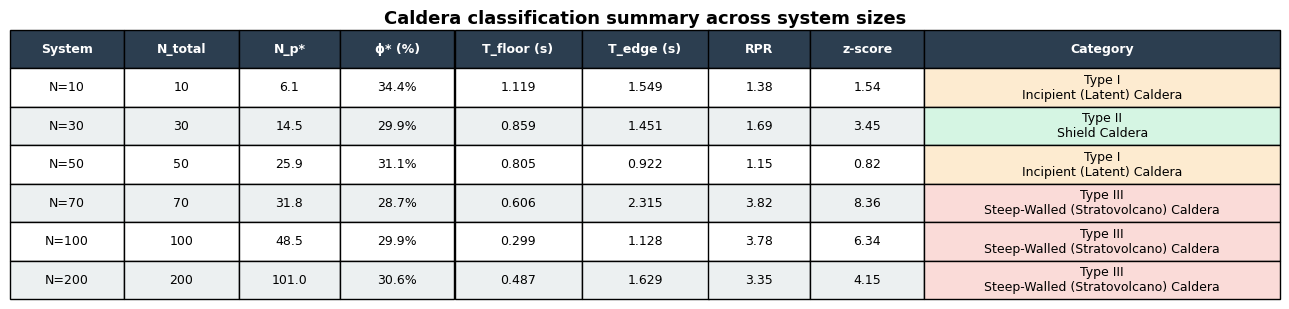

In [23]:
# ---- FIGURE 4: CALDERA CLASSIFICATION SUMMARY TABLE ----
# Assumes classify_caldera() and the per-system r["classification"] dicts
# already exist (see previous cell). Re-run classification here defensively
# in case this cell is executed standalone.

for name, r in results.items():
    if "classification" not in r:
        r["classification"] = classify_caldera(r)

fig4, ax_tab2 = plt.subplots(figsize=(13, 3.2))
ax_tab2.axis('off')

col_labels2 = ["System", "N_total", "N_p*", "\u03d5* (%)",
               "T_floor (s)", "T_edge (s)", "RPR", "z-score", "Category"]

table_data2 = []
for name, r in results.items():
    c = r["classification"]
    table_data2.append([
        name,
        f"{r['N_total']}",
        f"{r['Np_min']:.1f}",
        f"{r['phi_min']*100:.1f}%",
        f"{c['T_floor']:.3f}",
        f"{c['T_edge']:.3f}",
        f"{c['RPR']:.2f}",
        f"{c['z']:.2f}",
        c["category"].replace("Type ", "Type ").split(" \u2013 ")[0]
        + "\n" + c["category"].split(" \u2013 ")[1],
    ])

tbl2 = ax_tab2.table(
    cellText=table_data2,
    colLabels=col_labels2,
    cellLoc='center',
    loc='center',
    colWidths=[0.09, 0.09, 0.08, 0.09, 0.10, 0.10, 0.08, 0.09, 0.28]
)
tbl2.auto_set_font_size(False)
tbl2.set_fontsize(9)
tbl2.scale(1, 2.4)

# Style header
for j in range(len(col_labels2)):
    tbl2[0, j].set_facecolor('#2c3e50')
    tbl2[0, j].set_text_props(color='white', fontweight='bold')

# Color-code the Category column by type, and shade alternate rows elsewhere
type_colors = {
    "Type I": "#fdebd0",    # pale amber - latent
    "Type II": "#d5f5e3",   # pale green - shield
    "Type III": "#fadbd8",  # pale red - steep-walled
}
for i, row in enumerate(table_data2, start=1):
    cat_key = row[-1].split("\n")[0]
    for j in range(len(col_labels2)):
        if j == len(col_labels2) - 1:
            tbl2[i, j].set_facecolor(type_colors.get(cat_key, "white"))
        else:
            tbl2[i, j].set_facecolor('#ecf0f1' if i % 2 == 0 else 'white')

ax_tab2.set_title("Caldera classification summary across system sizes",
                   fontsize=13, fontweight='bold', pad=16)

plt.tight_layout()
# plt.savefig("caldera_classification_table.jpg", dpi=300, bbox_inches='tight')
# plt.savefig("caldera_classification_table.pdf", dpi=300, bbox_inches='tight')
print("Figure 4 (classification table) saved.")
plt.show()

C:\Users\VENSER\AppData\Local\Temp\ipykernel_15384\3670606890.py:32: UserWarning: You passed a edgecolor/edgecolors ('brown') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax_T.scatter(x_pos[i], d["T_floor"], marker=d["marker"], color=d["color"],
C:\Users\VENSER\AppData\Local\Temp\ipykernel_15384\3670606890.py:46: UserWarning: You passed a edgecolor/edgecolors ('brown') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax_SD.scatter(x_pos[i], d["SD_floor"], marker=d["marker"], color=d["color"],
C:\Users\VENSER\AppData\Local\Temp\ipykernel_15384\3670606890.py:58: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


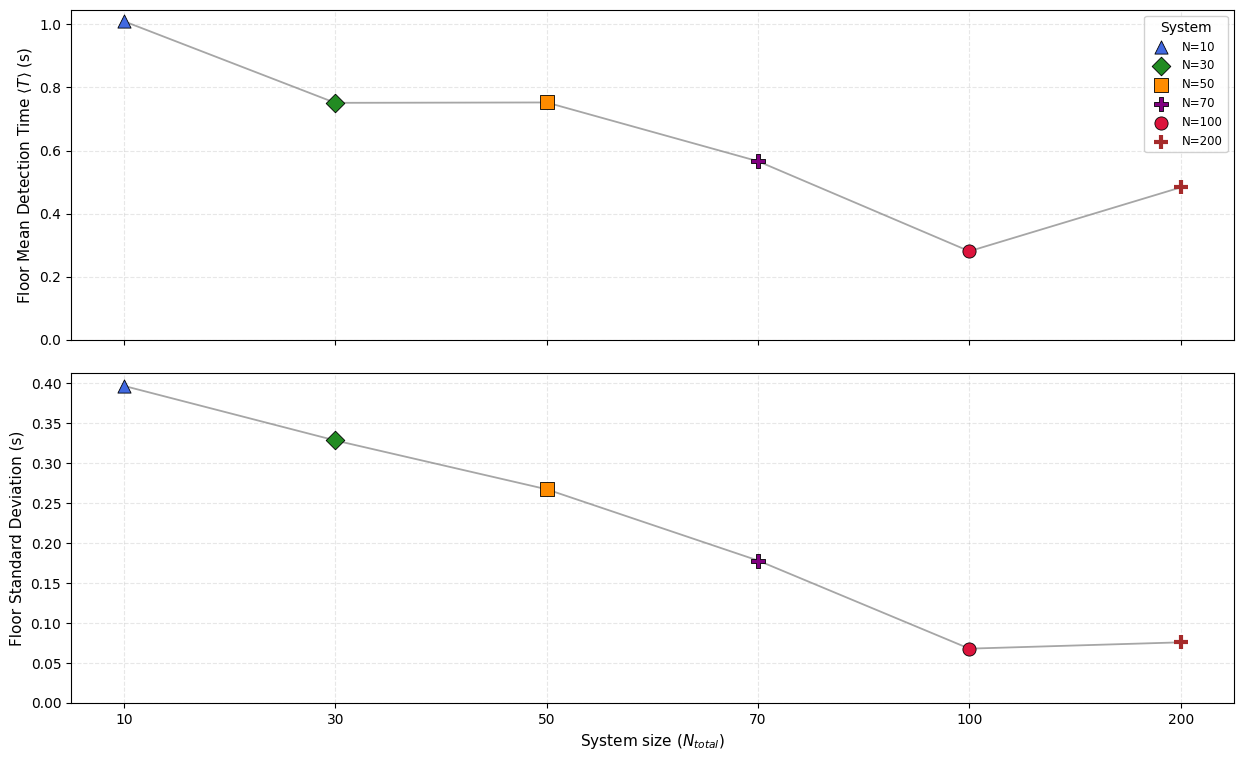

In [24]:
# ---- FLOOR SUMMARY: minimum detection time & its SD, across system sizes ----
floor_data = []
for name, r in results.items():
    floor_idx = np.argmin(r["mean"])          # lowest raw data point = caldera floor
    floor_data.append({
        "name"    : name,
        "N_total" : r["N_total"],
        "Np_floor": r["Np_arr"][floor_idx],
        "phi_floor": r["phi_arr"][floor_idx] * 100,
        "T_floor" : r["mean"][floor_idx],
        "SD_floor": r["std"][floor_idx],
        "color"   : r["color"],
        "marker"  : r["marker"],
    })

# Sort by system size so the trend across N_total reads left-to-right
floor_data.sort(key=lambda d: d["N_total"])

N_totals = [d["N_total"] for d in floor_data]
T_floors = [d["T_floor"] for d in floor_data]
SD_floors= [d["SD_floor"] for d in floor_data]

fig5, (ax_T, ax_SD) = plt.subplots(2, 1, figsize=(15, 9), sharex=True,
                                    gridspec_kw={"hspace": 0.1})

x_pos = np.arange(len(N_totals))

# Top: floor mean detection time
ax_T.plot(x_pos, T_floors, '-', color='gray', linewidth=1.3, alpha=0.7, zorder=2)
for i, d in enumerate(floor_data):
    is_plus_marker = d["marker"] in ('+', 'x')
    ax_T.scatter(x_pos[i], d["T_floor"], marker=d["marker"], color=d["color"],
                 s=90, zorder=3,
                 edgecolor='black' if not is_plus_marker else d["color"],
                 linewidths=3.0 if is_plus_marker else 0.6,
                 label=d["name"])
ax_T.set_ylabel(r"Floor Mean Detection Time $\langle T \rangle$ (s)", fontsize=11)
ax_T.grid(True, linestyle='--', alpha=0.3)
ax_T.set_ylim(bottom=0)
ax_T.legend(fontsize=8.5, loc='best', framealpha=0.9, title="System")

# Bottom: floor standard deviation
ax_SD.plot(x_pos, SD_floors, '-', color='gray', linewidth=1.3, alpha=0.7, zorder=2)
for i, d in enumerate(floor_data):
    is_plus_marker = d["marker"] in ('+', 'x')
    ax_SD.scatter(x_pos[i], d["SD_floor"], marker=d["marker"], color=d["color"],
                  s=90, zorder=3,
                  edgecolor='black' if not is_plus_marker else d["color"],
                  linewidths=3.0 if is_plus_marker else 0.6)
ax_SD.set_ylabel("Floor Standard Deviation (s)", fontsize=11)
ax_SD.set_xlabel("System size ($N_{total}$)", fontsize=11)
ax_SD.grid(True, linestyle='--', alpha=0.3)
ax_SD.set_ylim(bottom=0)

ax_SD.set_xticks(x_pos)
ax_SD.set_xticklabels([str(n) for n in N_totals])

plt.tight_layout()
plt.savefig("Fig5_floor_summary.png", dpi=300, bbox_inches='tight')
plt.show()